# Shallow Velocity Model (Cross-Section Plots)

This notebook is used to plot cross sections for the shallow velocity model to improvement of LA basin for UCVM

### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
import matplotlib.colors as mcolors
import matplotlib.tri as tri
import torch
import gpytorch
from pyproj import Proj, transform
from matplotlib import rcParams as rc
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from shapely.geometry import Polygon
import geopandas as gpd

#import user models
#from pylib_gp_twoscale import VelGPModel, Genevarikernel
from pylib_gp_twoscale import VelGPModel, Genevarikernel

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Times New Roman'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 16,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
norm = mcolors.Normalize(vmin=150., vmax=2000.)  
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

In [3]:
# define cross-section location
fn_crssect_loc   = '../Data/Raw_data/cross_section.csv'
crssect_loc = pd.read_csv(fn_crssect_loc)

#get corresponding coordinates
id = 1
def get_crssect_coords(crssect_loc, target_id):
    subset = crssect_loc[crssect_loc['cross_id'] == target_id]

    crssect_str = subset.iloc[0][['x', 'y']].tolist()
    crssect_end = subset.iloc[1][['x', 'y']].tolist()
    return crssect_str, crssect_end

crssect_str, crssect_end = get_crssect_coords(crssect_loc, id)

In [4]:
#define corss-section
name_crssect = 'Cross Section ' + str(id)
fname_crssect = name_crssect.lower().replace(' ','_')

#cross-section extents
crssect_depth = [0, 500]

#descritization
crssect_npt_xy = 100
crssect_npt_z  = 20
crs_grid = []

#model directory
dir_model = '../Model_training/'

#model column names (input, output)
cn_x = ['vs_depth','Z_2.5','surf_elevation','easting','northing'] #output
cn_y = 'diff'                                                     #input

#define output directories
dir_out = '../Data/Vel_data/'
dir_fig = '../Data/Figure/'

### Cross-Section Geometry

In [5]:
#create x,y,z grid
points_xy = np.linspace(crssect_str, crssect_end, crssect_npt_xy)
points_z = np.linspace(crssect_depth[0], crssect_depth[1], crssect_npt_z)

for x, y in points_xy:
    for z in points_z:
        crs_grid.append([x, y, z])

#wite geometry for ucvm query
with open(dir_out+'Cross_section_input'+'/'+fname_crssect+'_ucvm_input.txt', "w", encoding="utf-8") as file:
    for i in crs_grid:
        file.write(" ".join(map(str, i)) + "\n") 

### Load UCVM Model

In [6]:
df_ucvm = pd.read_csv(dir_out+'Cross_section_input'+'/'+fname_crssect+'_ucvm_output.txt', sep=r'\s+', 
                      header=None,
                      names=['long','lat','vs_depth','site_elevation','vs30',
                             'cvm','cvm_vp','cvm_vs','cvm_dens',
                             'gtl','gtl_vp','gtl_vs','gtl_dens',
                             'alg','vp','vs','dens'])

# get the UTM coordinate
def longlat_to_utm(lon, lat):
    utm_zone = int((lon + 180) / 6) + 1
    proj = Proj(proj='utm', zone=utm_zone, ellps='WGS84')
    easting, northing = proj(lon, lat)
    return easting, northing

df_ucvm[['easting', 'northing']] = df_ucvm.apply(lambda row: pd.Series(longlat_to_utm(row['long'], row['lat'])), axis=1)

df_ucvm['distance'] = np.linalg.norm((df_ucvm[['easting','northing']] - df_ucvm.loc[0,['easting','northing']]).values.astype(float), 
                                     axis=1)

df_ucvm

,long,lat,vs_depth,site_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,gtl_vp,gtl_vs,gtl_dens,alg,vp,vs,dens,easting,northing,distance
0,-117.2946,34.1861,0.000,522.347,579.862,cvms5,1310.405,825.000,2017.052,none,0.0,0.0,0.0,crust,1310.405,825.000,2017.052,472853.756347,3.782830e+06,0.000000
1,-117.2946,34.1861,26.316,522.347,579.862,cvms5,1453.439,904.240,2058.210,none,0.0,0.0,0.0,crust,1453.439,904.240,2058.210,472853.756347,3.782830e+06,0.000000
2,-117.2946,34.1861,52.632,522.347,579.862,cvms5,1596.474,983.480,2095.441,none,0.0,0.0,0.0,crust,1596.474,983.480,2095.441,472853.756347,3.782830e+06,0.000000
3,-117.2946,34.1861,78.947,522.347,579.862,cvms5,1739.508,1062.720,2129.011,none,0.0,0.0,0.0,crust,1739.508,1062.720,2129.011,472853.756347,3.782830e+06,0.000000
4,-117.2946,34.1861,105.263,522.347,579.862,cvms5,1882.542,1141.959,2159.192,none,0.0,0.0,0.0,crust,1882.542,1141.959,2159.192,472853.756347,3.782830e+06,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-117.2946,34.0531,394.737,305.461,286.087,cvms5,4075.404,2323.577,2387.869,none,0.0,0.0,0.0,crust,4075.404,2323.577,2387.869,472811.223522,3.768083e+06,14747.197957
1996,-117.2946,34.0531,421.053,305.461,286.087,cvms5,4239.315,2419.438,2402.416,none,0.0,0.0,0.0,crust,4239.315,2419.438,2402.416,472811.223522,3.768083e+06,14747.197957
1997,-117.2946,34.0531,447.368,305.461,286.087,cvms5,4403.226,2515.299,2418.251,none,0.0,0.0,0.0,crust,4403.226,2515.299,2418.251,472811.223522,3.768083e+06,14747.197957
1998,-117.2946,34.0531,473.684,305.461,286.087,cvms5,4567.136,2611.160,2435.684,none,0.0,0.0,0.0,crust,4567.136,2611.160,2435.684,472811.223522,3.768083e+06,14747.197957


### Load Training Data (Vs Measurements)

In [7]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
0,610,1.00,155.0,0.5,1.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,938.187,251.052,2380.0,-1.800524,2
1,610,2.00,170.2,1.5,2.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.068,251.052,2380.0,-1.707914,2
2,610,3.00,196.5,2.5,3.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.949,251.052,2380.0,-1.565163,2
3,610,4.00,191.9,3.5,4.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,940.830,251.052,2380.0,-1.589788,2
4,610,5.00,202.0,4.5,5.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,941.711,251.052,2380.0,-1.539431,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,2479,12.60,354.0,9.3,15.9,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,894.882,54.938,3620.0,-0.927395,1
11027,2479,21.15,387.0,15.9,26.4,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,899.010,54.938,3620.0,-0.842869,1
11028,2479,34.80,445.0,26.4,43.2,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,905.600,54.938,3620.0,-0.710523,1
11029,2479,56.60,540.0,43.2,70.0,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,916.125,54.938,3620.0,-0.528584,1


In [8]:
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1


In [9]:
df_sonic = pd.read_csv(dir_out+'Training_data/df_sonic.txt', encoding='utf-8')
df_sonic = df_sonic.rename(columns={'X': 'easting', 'Y': 'northing',
                                       'depth': 'vs_depth'})
df_sonic = df_sonic[['vs_depth','Z_2.5','surf_elevation','easting','northing','diff',  'velocity_metadata_id']]

df_sonic['basin_idnum'] = 1
df_sonic

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,basin_idnum
0,67.124000,4400.0,23.596,387402.0000,3753149.500,0.010634,-29,1
1,77.124000,4400.0,23.596,387402.0000,3753149.500,0.018006,-29,1
2,87.124000,4400.0,23.596,387402.0000,3753149.500,0.028627,-29,1
3,97.124000,4400.0,23.596,387402.0000,3753149.500,0.040313,-29,1
4,107.124000,4400.0,23.596,387402.0000,3753149.500,0.051009,-29,1
...,...,...,...,...,...,...,...,...
3177,1956.730197,2500.0,83.353,387298.0938,3767711.984,-0.116894,-28,1
3178,1966.730197,2500.0,83.353,387298.0938,3767711.984,-0.056673,-28,1
3179,1976.730197,2500.0,83.353,387298.0938,3767711.984,-0.040450,-28,1
3180,1986.730197,2500.0,83.353,387298.0938,3767711.984,-0.050204,-28,1


In [10]:
df_veldata = pd.concat([df_measure.reset_index(drop=True), df_sonic.reset_index(drop=True)], ignore_index=True, sort=False)
df_veldata

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
14208,1956.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.116894,-28,NaN,1
14209,1966.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.056673,-28,NaN,1
14210,1976.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.040450,-28,NaN,1
14211,1986.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.050204,-28,NaN,1


### Load and Define GP Model

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#read model
scaler_input = load(open(dir_model+'ucvm_la_basin_adj_scaler_frozen.pkl', 'rb'))
model_state = torch.load(dir_model+'ucvm_la_basin_adj_model_frozen_newloss.pth', weights_only=True)

#get training input/output
X_train = scaler_input.transform(df_veldata.loc[:,cn_x].values)
Y_train = df_veldata.loc[:,cn_y].values
#convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float64)
Y_train = torch.tensor(Y_train, dtype=torch.float64)

basin_col = torch.tensor(
    df_veldata['basin_idnum'].to_numpy(),
    dtype=X_train.dtype,
    device=X_train.device
).unsqueeze(1)

X_train = torch.cat([X_train, basin_col], dim=1)
print(X_train)

#define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device).double()
model = VelGPModel(X_train, Y_train, likelihood).to(device).double()
model.load_state_dict(model_state)

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [30.8894, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.0499, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.2105, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000]],
       dtype=torch.float64)


<All keys matched successfully>

### get the information of each coordinate

In [12]:
# output the coordinate to get the Z_2.5
with open(dir_out+'Cross_section_input'+'/'+fname_crssect+'_ucvm_input_Z2.5.txt', "w", encoding="utf-8") as file:
    for i in points_xy:
        file.write(" ".join(map(str, i)) + "\n") 

In [13]:
# append the Z_2.5 into dataframe
Z25_data = np.loadtxt(dir_out+'Cross_section_input'+'/'+fname_crssect+'_ucvm_output_Z2.5.txt')  
z_repeated = np.repeat(Z25_data[:, 2], crssect_npt_z)
#z_repeated = Z25_data[:, 2]
df_ucvm['Z_2.5'] = z_repeated

In [14]:
df_ucvm = df_ucvm.rename(columns={'site_elevation': 'surf_elevation'})
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,gtl_vs,gtl_dens,alg,vp,vs,dens,easting,northing,distance,Z_2.5
0,-117.2946,34.1861,0.000,522.347,579.862,cvms5,1310.405,825.000,2017.052,none,...,0.0,0.0,crust,1310.405,825.000,2017.052,472853.756347,3.782830e+06,0.000000,1520.0
1,-117.2946,34.1861,26.316,522.347,579.862,cvms5,1453.439,904.240,2058.210,none,...,0.0,0.0,crust,1453.439,904.240,2058.210,472853.756347,3.782830e+06,0.000000,1520.0
2,-117.2946,34.1861,52.632,522.347,579.862,cvms5,1596.474,983.480,2095.441,none,...,0.0,0.0,crust,1596.474,983.480,2095.441,472853.756347,3.782830e+06,0.000000,1520.0
3,-117.2946,34.1861,78.947,522.347,579.862,cvms5,1739.508,1062.720,2129.011,none,...,0.0,0.0,crust,1739.508,1062.720,2129.011,472853.756347,3.782830e+06,0.000000,1520.0
4,-117.2946,34.1861,105.263,522.347,579.862,cvms5,1882.542,1141.959,2159.192,none,...,0.0,0.0,crust,1882.542,1141.959,2159.192,472853.756347,3.782830e+06,0.000000,1520.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-117.2946,34.0531,394.737,305.461,286.087,cvms5,4075.404,2323.577,2387.869,none,...,0.0,0.0,crust,4075.404,2323.577,2387.869,472811.223522,3.768083e+06,14747.197957,460.0
1996,-117.2946,34.0531,421.053,305.461,286.087,cvms5,4239.315,2419.438,2402.416,none,...,0.0,0.0,crust,4239.315,2419.438,2402.416,472811.223522,3.768083e+06,14747.197957,460.0
1997,-117.2946,34.0531,447.368,305.461,286.087,cvms5,4403.226,2515.299,2418.251,none,...,0.0,0.0,crust,4403.226,2515.299,2418.251,472811.223522,3.768083e+06,14747.197957,460.0
1998,-117.2946,34.0531,473.684,305.461,286.087,cvms5,4567.136,2611.160,2435.684,none,...,0.0,0.0,crust,4567.136,2611.160,2435.684,472811.223522,3.768083e+06,14747.197957,460.0


In [15]:
gdf_basins = gpd.read_file("../Data/Raw_data/Basins/LA_Basins_merged3.shp")

gdf_basins_utm = gdf_basins.to_crs(epsg=32611)


gdf_pts = gpd.GeoDataFrame(
    df_ucvm.copy(),
    geometry=gpd.points_from_xy(df_ucvm["easting"], df_ucvm["northing"]),
    crs="EPSG:32611"  
)


basin_cols = ["OBJECTID", "Basin_Numb", "Basin_Name", "geometry"]
gdf_basin_small = gdf_basins_utm[basin_cols].copy()


joined = gpd.sjoin(
    gdf_pts,
    gdf_basin_small,
    how="left",
    predicate="within" 
)

joined


,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,dens,easting,northing,distance,Z_2.5,geometry,index_right,OBJECTID,Basin_Numb,Basin_Name
0,-117.2946,34.1861,0.000,522.347,579.862,cvms5,1310.405,825.000,2017.052,none,...,2017.052,472853.756347,3.782830e+06,0.000000,1520.0,POINT (472853.756 3782829.903),NaN,NaN,NaN,NaN
1,-117.2946,34.1861,26.316,522.347,579.862,cvms5,1453.439,904.240,2058.210,none,...,2058.210,472853.756347,3.782830e+06,0.000000,1520.0,POINT (472853.756 3782829.903),NaN,NaN,NaN,NaN
2,-117.2946,34.1861,52.632,522.347,579.862,cvms5,1596.474,983.480,2095.441,none,...,2095.441,472853.756347,3.782830e+06,0.000000,1520.0,POINT (472853.756 3782829.903),NaN,NaN,NaN,NaN
3,-117.2946,34.1861,78.947,522.347,579.862,cvms5,1739.508,1062.720,2129.011,none,...,2129.011,472853.756347,3.782830e+06,0.000000,1520.0,POINT (472853.756 3782829.903),NaN,NaN,NaN,NaN
4,-117.2946,34.1861,105.263,522.347,579.862,cvms5,1882.542,1141.959,2159.192,none,...,2159.192,472853.756347,3.782830e+06,0.000000,1520.0,POINT (472853.756 3782829.903),NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-117.2946,34.0531,394.737,305.461,286.087,cvms5,4075.404,2323.577,2387.869,none,...,2387.869,472811.223522,3.768083e+06,14747.197957,460.0,POINT (472811.224 3768082.767),5.0,4.0,8-002,UPPER SANTA ANA VALLEY - SAN BERNARDINO
1996,-117.2946,34.0531,421.053,305.461,286.087,cvms5,4239.315,2419.438,2402.416,none,...,2402.416,472811.223522,3.768083e+06,14747.197957,460.0,POINT (472811.224 3768082.767),5.0,4.0,8-002,UPPER SANTA ANA VALLEY - SAN BERNARDINO
1997,-117.2946,34.0531,447.368,305.461,286.087,cvms5,4403.226,2515.299,2418.251,none,...,2418.251,472811.223522,3.768083e+06,14747.197957,460.0,POINT (472811.224 3768082.767),5.0,4.0,8-002,UPPER SANTA ANA VALLEY - SAN BERNARDINO
1998,-117.2946,34.0531,473.684,305.461,286.087,cvms5,4567.136,2611.160,2435.684,none,...,2435.684,472811.223522,3.768083e+06,14747.197957,460.0,POINT (472811.224 3768082.767),5.0,4.0,8-002,UPPER SANTA ANA VALLEY - SAN BERNARDINO


In [16]:
df_ucvm['basin_idnum'] = joined['OBJECTID']
mask_nan = df_ucvm["basin_idnum"].isna()
gdf_pts_nan = gdf_pts.loc[mask_nan].copy()

if len(gdf_pts_nan) > 0:
    nearest = gpd.sjoin_nearest(
        gdf_pts_nan,
        gdf_basin_small,
        how="left",
        distance_col="dist_to_basin_m"
    )

    basin_fill = np.where(
        nearest["dist_to_basin_m"] <= 1000,
        nearest["OBJECTID"],
        0)
    df_ucvm.loc[mask_nan, "basin_idnum"] = basin_fill

df_ucvm["basin_idnum"] = df_ucvm["basin_idnum"].astype(int)
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,gtl_dens,alg,vp,vs,dens,easting,northing,distance,Z_2.5,basin_idnum
0,-117.2946,34.1861,0.000,522.347,579.862,cvms5,1310.405,825.000,2017.052,none,...,0.0,crust,1310.405,825.000,2017.052,472853.756347,3.782830e+06,0.000000,1520.0,4
1,-117.2946,34.1861,26.316,522.347,579.862,cvms5,1453.439,904.240,2058.210,none,...,0.0,crust,1453.439,904.240,2058.210,472853.756347,3.782830e+06,0.000000,1520.0,4
2,-117.2946,34.1861,52.632,522.347,579.862,cvms5,1596.474,983.480,2095.441,none,...,0.0,crust,1596.474,983.480,2095.441,472853.756347,3.782830e+06,0.000000,1520.0,4
3,-117.2946,34.1861,78.947,522.347,579.862,cvms5,1739.508,1062.720,2129.011,none,...,0.0,crust,1739.508,1062.720,2129.011,472853.756347,3.782830e+06,0.000000,1520.0,4
4,-117.2946,34.1861,105.263,522.347,579.862,cvms5,1882.542,1141.959,2159.192,none,...,0.0,crust,1882.542,1141.959,2159.192,472853.756347,3.782830e+06,0.000000,1520.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,-117.2946,34.0531,394.737,305.461,286.087,cvms5,4075.404,2323.577,2387.869,none,...,0.0,crust,4075.404,2323.577,2387.869,472811.223522,3.768083e+06,14747.197957,460.0,4
1996,-117.2946,34.0531,421.053,305.461,286.087,cvms5,4239.315,2419.438,2402.416,none,...,0.0,crust,4239.315,2419.438,2402.416,472811.223522,3.768083e+06,14747.197957,460.0,4
1997,-117.2946,34.0531,447.368,305.461,286.087,cvms5,4403.226,2515.299,2418.251,none,...,0.0,crust,4403.226,2515.299,2418.251,472811.223522,3.768083e+06,14747.197957,460.0,4
1998,-117.2946,34.0531,473.684,305.461,286.087,cvms5,4567.136,2611.160,2435.684,none,...,0.0,crust,4567.136,2611.160,2435.684,472811.223522,3.768083e+06,14747.197957,460.0,4


### Evaluate GP for Cross Section

In [17]:
X_train_cross = torch.tensor(scaler_input.transform(df_ucvm.loc[:,cn_x].values), dtype=torch.float64)
Y_train_cross = df_ucvm['cvm_vs'].values
Y_train_cross

basin_col = torch.tensor(
    df_ucvm['basin_idnum'].to_numpy(),
    dtype=X_train_cross.dtype,
    device=X_train_cross.device
).unsqueeze(1)

X_train_cross = torch.cat([X_train_cross, basin_col], dim=1)
print(X_train_cross)


X_train_cross.max(axis=0)
X_train.max(axis=0)


df_veldata.loc[:,cn_x].values.max(axis=0)
df_veldata.loc[df_veldata.vs_depth > 380,:].velocity_metadata_id.unique()

tensor([[-8.4179e-01, -7.9684e-01,  1.6645e+00,  3.1314e+00,  3.6759e-01,
          4.0000e+00],
        [-4.1936e-01, -7.9684e-01,  1.6645e+00,  3.1314e+00,  3.6759e-01,
          4.0000e+00],
        [ 3.0755e-03, -7.9684e-01,  1.6645e+00,  3.1314e+00,  3.6759e-01,
          4.0000e+00],
        ...,
        [ 6.3395e+00, -1.5505e+00,  5.2404e-01,  3.1300e+00, -1.4378e-01,
          4.0000e+00],
        [ 6.7620e+00, -1.5505e+00,  5.2404e-01,  3.1300e+00, -1.4378e-01,
          4.0000e+00],
        [ 7.1844e+00, -1.5505e+00,  5.2404e-01,  3.1300e+00, -1.4378e-01,
          4.0000e+00]], dtype=torch.float64)


array([-29, -30, -31, -32, -33,  -1,  -2,  -3,  -4,  -5,  -6,  -7,  -8,
        -9, -10, -11, -12, -13, -14, -15, -16, -17, -18, -19, -22, -23,
       -24, -25, -26, -27, -28])

In [18]:
#train GP model
model.eval()
likelihood.eval()

with torch.no_grad():
    observed_pred = likelihood(model(X_train_cross.to(device).double()))
    predict_value = observed_pred.mean.detach().cpu()

    #std = observed_pred.stddev.detach().cpu()

    #samples = model(X_train_cross.to(device).double()).rsample(torch.Size([3]))
    #fstd = model(X_train_cross.to(device).double()).stddev

In [19]:
df_ucvm['predict_diff'] = predict_value
#df_ucvm['predict_vs'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff"].to_numpy()*df_ucvm['factor'])
df_ucvm['predict_vs'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff"].to_numpy())

### Comparasion for UCVM and GP model

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

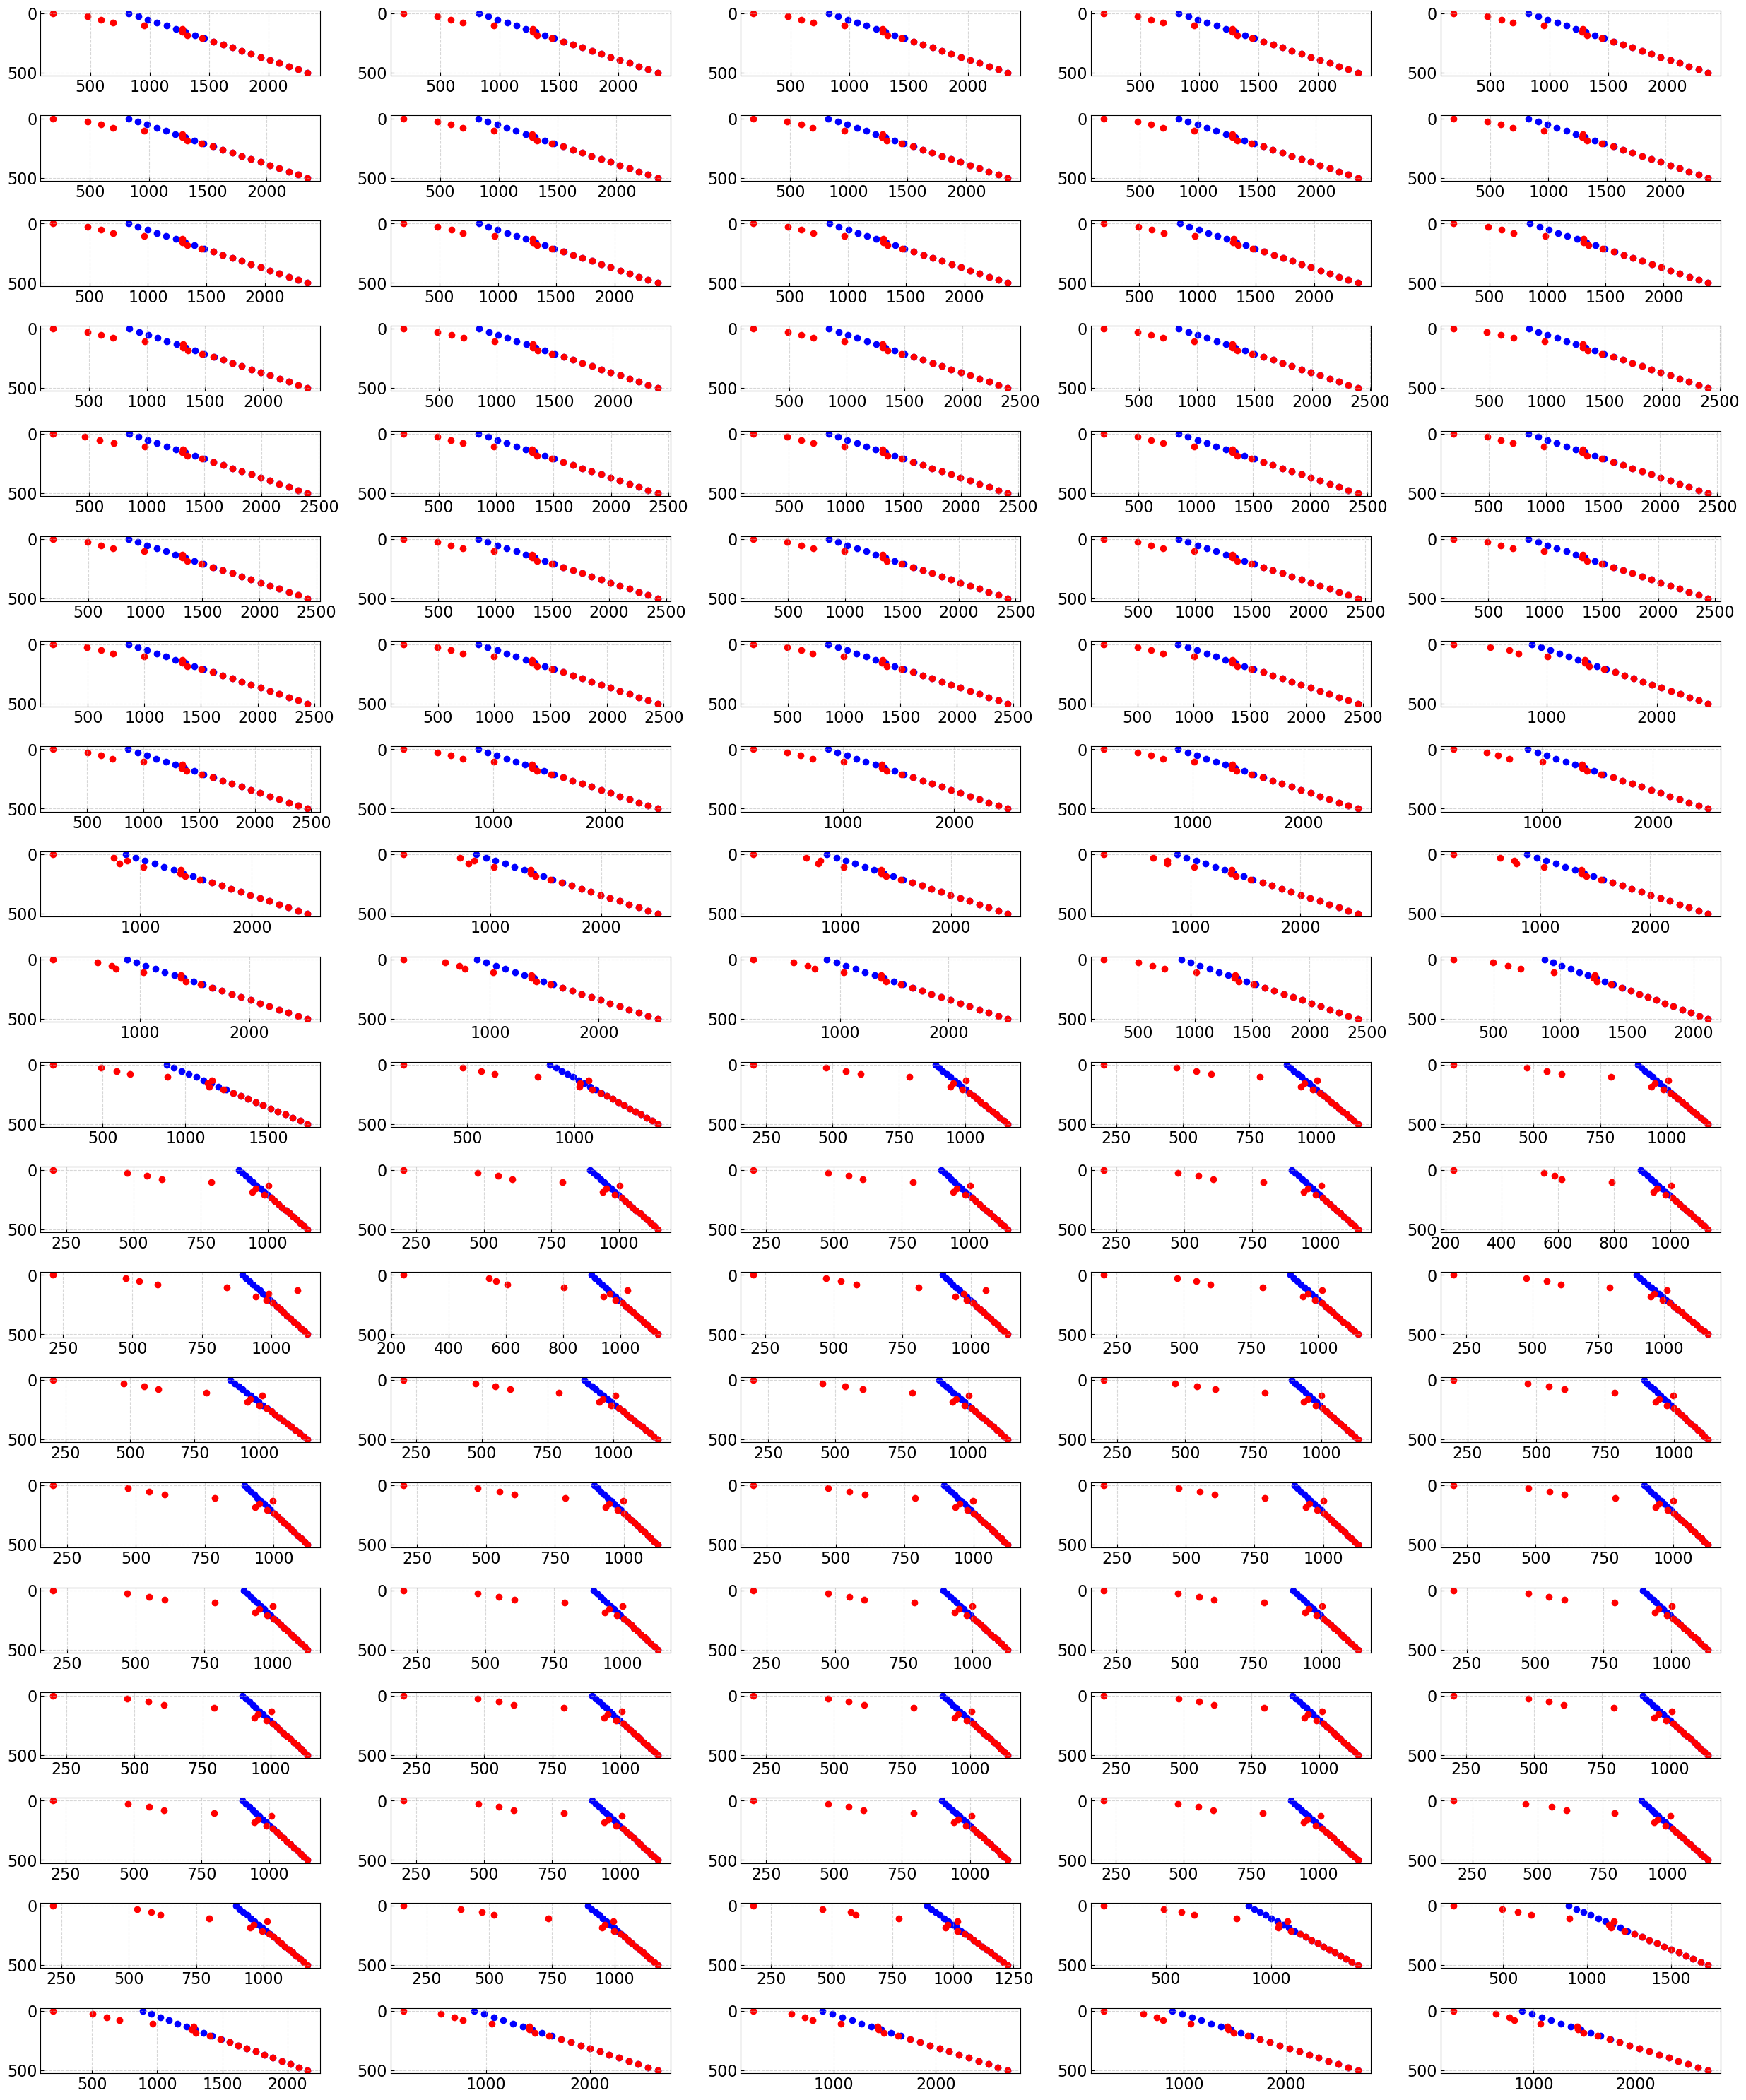

In [20]:
#compare in each file
num_plots = len(df_ucvm) // crssect_npt_z  
fig, axes = plt.subplots(20, 5, figsize=(25, 30))  
axes = axes.flatten() 

for i in range(num_plots):
    start = i * crssect_npt_z
    end = start + crssect_npt_z
    sub_df = df_ucvm.iloc[start:end]
    ax = axes[i]  
    ax.invert_yaxis() 
    ax.scatter(sub_df['cvm_vs'], sub_df['vs_depth'], color='blue')
    ax.scatter(sub_df['predict_vs'], sub_df['vs_depth'], color='red')
    #ax.set_title(data_final.loc[i, 'site_name'], fontsize=10) 
    #ax.legend(fontsize=8)  

plt.tight_layout()
plt.show()


#### Cross Section GP Model

In [21]:
distance = df_ucvm['distance'].values/1000
depth = df_ucvm['vs_depth'].values

X = np.reshape(distance, [crssect_npt_xy, crssect_npt_z]).T
Y = np.reshape(depth, [crssect_npt_xy, crssect_npt_z]).T
Z_model = np.reshape(df_ucvm['predict_vs'].values, [crssect_npt_xy, crssect_npt_z]).T
Z_ucvm  = np.reshape(df_ucvm['vs'].values, [crssect_npt_xy, crssect_npt_z]).T
#Z_model = np.minimum(Z_model, Z_ucvm)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'sans-serif' not found because none of the following fa

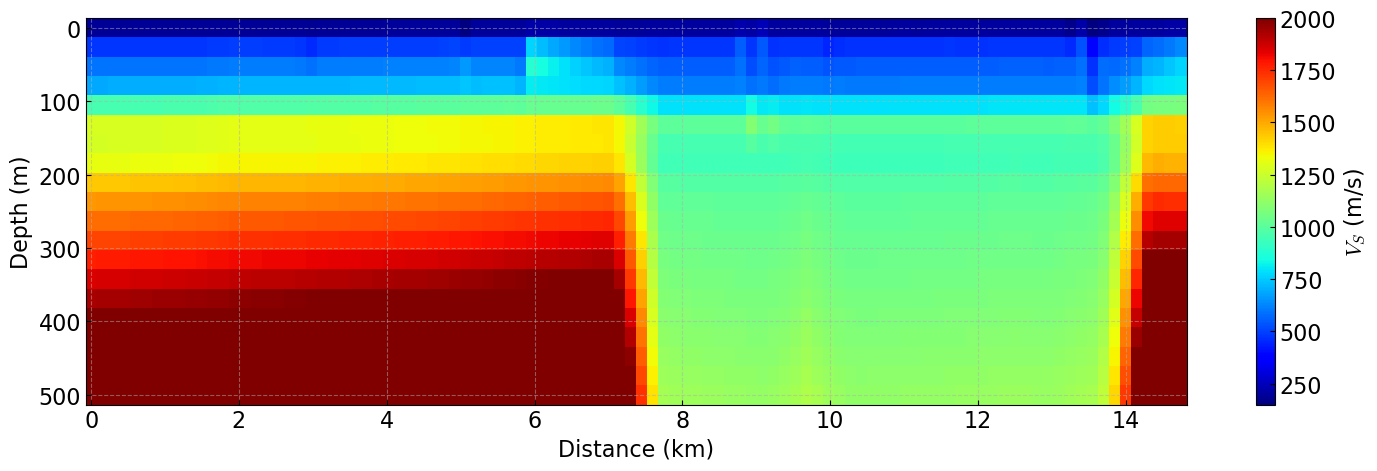

In [22]:
cmap = plt.get_cmap("jet")
norm = mcolors.Normalize(vmin=150., vmax=2000.)  

fig, ax = plt.subplots(figsize=(15., 5.))
c = ax.pcolormesh(X, Y, Z_model, cmap=cmap, norm=norm, shading='auto')
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.invert_yaxis()  
fig.colorbar(c, ax=ax, label="$V_S$ (m/s)")
plt.tight_layout()
#plt.savefig(dir_fig+'cross_section'+str(id)+'_GPmodel.png', format='png', dpi=300)
plt.show()

# Output model

In [23]:
df_ucvm.to_csv(dir_out+'Cross_section_results/'+str(id)+'_vs_data_cross_section.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')